# IEOR4500 — Project 4
## Optimization: Convex Portfolio Selection and Nonconvex Model Fitting


### Objective of this project

Apply and **systematically compare multiple optimization algorithms** under a fixed iteration budget. Your goal is to achieve the **lowest valid objective value** after the prescribed number of iterations. You must also analyze convergence, hyperparameter sensitivity, computation, and feasibility.

You will solve two problems:

1. **Convex portfolio optimization** with long-only and fully invested constraints.
2. **Nonconvex optimization** arising from a small, fixed neural-network prediction model.

**Implementation requirement:** Your team must implement **at least one complete optimization algorithm from scratch**. For this project, you are required to implement **Projected Gradient Descent (PGD)** for Problem 1, including its parameter update and projection. You may use NumPy/PyTorch for arrays, automatic differentiation, and linear algebra, but a built-in optimizer step followed by projection **does not count** as the required manual PGD implementation. Additional custom implementations are welcome.

For the remaining experiments, you are encouraged to use appropriate **built-in optimization methods**. You are **not** expected to reimplement all standard optimizers.

### Rules for fair comparisons

- Use the **provided data, objectives, constraints, and initial parameters** unchanged for every algorithm. Do not modify the problem to obtain a smaller objective value.
- You may tune optimization settings: learning rates, step-size schedules, momentum coefficients, minibatch sizes, line-search settings, penalty parameters, and solver options.
- **Score the original objective**, not a penalized surrogate or an individual minibatch loss. Record the original objective at the specified checkpoints. For the portfolio problem, compare the projected first-order methods under the fixed-iteration budget; use the SciPy constrained solver primarily as an accuracy/reference benchmark and the penalty method as a feasibility diagnostic.
- For **Problem 1**, a candidate is feasible only if $w_i\ge -10^{-6}$ for all $i$ and $|\sum_i w_i-1|\le10^{-6}$. An infeasible candidate cannot be ranked as a valid portfolio solution, even if its objective value is lower.
- **Iteration budgets:** at most **100 optimization iterations** for Problem 1, and at most **200 parameter-update iterations** for Problem 2. If an algorithm converges early, report its final result and the actual number of iterations.
- One iteration is **not equally expensive** for all algorithms. In addition to the iteration-based comparisons, report wall-clock time and objective/gradient evaluation counts where accessible. Some line searches and L-BFGS steps perform multiple evaluations.
- For standard first-order methods (e.g., SGD, Momentum, AdaGrad, and Adam), report the objective value after the specified number of iterations. For L-BFGS and other built-in quasi-Newton solvers, you may use their default or tuned iteration and line-search settings. Since a single iteration may involve multiple objective and gradient evaluations, report the number of iterations (`nit`), function evaluations (`nfev`), and gradient evaluations (`njev`) when available, or the number of closure evaluations for PyTorch L-BFGS. Also report the runtime to help compare computational efficiency across methods.
- All methods must start from the prescribed initialization. For stochastic methods, use reproducible random seeds and explain how minibatches are sampled.
- Do **not** add unrequested weight decay or alter the prescribed regularization term. A different training objective is not a valid comparison.

**Algorithm coverage:** The tasks below specify the methods/approaches that **every team is expected to attempt**. Do not stop after obtaining a good result with only two or three methods. Document unsuccessful or unstable tuning trials as well as successful ones.

**Tuning:** Conduct a meaningful hyperparameter search for each method, not just one untuned run. Report the settings tried and identify the best configuration under the stated budget.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=5, suppress=True)
print('NumPy:', np.__version__)
print('PyTorch:', torch.__version__)

NumPy: 2.3.5
PyTorch: 2.14.1+cpu


---
# Problem 1 — Convex Portfolio Optimization

### Background

A portfolio manager allocates capital to $n$ risky assets. Let $\mu\in\mathbb R^n$ be their estimated annualized expected returns and let $\Sigma\in\mathbb R^{n\times n}$ be the annualized covariance matrix. We balance expected return and variance by minimizing

$$
\boxed{F(w)=-\mu^\top w+\frac{\gamma}{2}w^\top\Sigma w}
$$

subject to

$$
w_i\ge0 \quad(i=1,\ldots,n),\qquad \sum_{i=1}^n w_i=1.
$$

This is a **convex quadratic optimization problem**. We use the same fixed simulated return data for every team and every algorithm. The synthetic data avoid external downloading or changing market histories.

**Fixed problem:** 60 assets, 504 daily observations, and $\gamma=8$. The provided functions define the exact objective and gradient to use.

In [2]:
# Fixed portfolio data — do not modify.
rng_p = np.random.default_rng(4500)
T, n_assets, n_factors = 504, 60, 5
true_mu = np.clip(rng_p.normal(0.075, 0.03, size=n_assets), 0.015, 0.14)

factors = rng_p.standard_normal((T, n_factors))
factors -= factors.mean(axis=0)
loadings = rng_p.normal(size=(n_factors, n_assets)) / np.sqrt(n_factors)
idiosyncratic = rng_p.standard_normal((T, n_assets))
idiosyncratic -= idiosyncratic.mean(axis=0)

returns = true_mu[None, :] / 252 + 0.012 * (factors @ loadings) + 0.008 * idiosyncratic
mu = 252 * returns.mean(axis=0)
Sigma = 252 * np.cov(returns, rowvar=False)
gamma = 8.0
w_init = np.ones(n_assets, dtype=float) / n_assets

print(f'{n_assets} assets, {T} observations')
print('Smallest covariance eigenvalue:', np.linalg.eigvalsh(Sigma).min())

60 assets, 504 observations
Smallest covariance eigenvalue: 0.007134254176514571


In [3]:
# The original objective and its gradient are fixed for all methods.
def portfolio_objective_np(w):
    w = np.asarray(w, dtype=float)
    return float(-mu @ w + 0.5 * gamma * (w @ Sigma @ w))

def portfolio_gradient_np(w):
    w = np.asarray(w, dtype=float)
    return -mu + gamma * (Sigma @ w)

mu_t = torch.tensor(mu, dtype=torch.float64)
Sigma_t = torch.tensor(Sigma, dtype=torch.float64)

def portfolio_objective_torch(w):
    return -(mu_t @ w) + 0.5 * gamma * (w @ Sigma_t @ w)

def portfolio_violations(w):
    w = np.asarray(w, dtype=float)
    return {
        'nonnegative_violation': float(np.maximum(-w, 0.0).max()),
        'budget_violation': float(abs(w.sum() - 1.0)),
    }

def portfolio_valid(w, tolerance=1e-6):
    return max(portfolio_violations(w).values()) <= tolerance

print('Initial portfolio objective:', portfolio_objective_np(w_init))
print('Initial constraint violations:', portfolio_violations(w_init))
assert np.isclose(portfolio_objective_torch(torch.tensor(w_init)).item(),
                  portfolio_objective_np(w_init), atol=1e-12)

Initial portfolio objective: -0.06724570955531894
Initial constraint violations: {'nonnegative_violation': 0.0, 'budget_violation': 0.0}


### Task 1 — Required algorithm comparisons (100 iterations)

**Every team must attempt all of the following:**

1. **Manual Projected Gradient Descent (PGD).** Implement the gradient update and Euclidean projection onto the feasible set yourselves. This is the **required from-scratch optimizer**.
2. **Projected Momentum.** Use a built-in optimizer (e.g., PyTorch SGD with momentum), combined with the appropriate projection.
3. **Projected Adam.** Use built-in Adam, combined with the appropriate projection.
4. **A built-in constrained solver (reference benchmark).** Use `scipy.optimize.minimize` with a method supporting the required constraints (e.g., `SLSQP`). This demonstrates what a dedicated constrained solver can achieve; report its iterations and evaluations, but do not treat it as a fair substitute for tuning projected first-order methods.
5. **A squared-penalty approach (feasibility comparison).** Use a standard unconstrained optimizer on a penalized objective. Report the **original** objective and constraint violations; discuss whether the penalty solution is feasible under the given tolerance.

**Additional reference (encouraged, but not a substitute for any of the above):** Use CVXPY or another convex QP solver to estimate a reference optimal value. Distinguish this solver benchmark from fixed-iteration method comparisons.

**Experiment requirements**

- Start all algorithms at the given $w_0=(1/n,\ldots,1/n)$.
- Tune learning rates/schedules, momentum or adaptive settings, solver settings, and penalty parameters as appropriate.
- Report the **original objective value at iterations 0, 20, 50, and 100**, or the final value if a solver terminates early. Report feasibility, computation time, and evaluation counts when available.
- Compare **PGD, projected Momentum, and projected Adam** by their **feasible original objective values** at the fixed iteration checkpoints. Report the dedicated SciPy solver separately as a numerical reference; include the penalty method to analyze constraint satisfaction. Show violations for *all* approaches.
- Plot objective versus iteration, clearly identifying infeasible iterates (if any). Explain meaningful differences in convergence and computational cost.

**You must write the optimization code and projection yourselves for the manual PGD experiment.**

In [4]:
# TODO — Problem 1
# Implement and tune every required method listed above.
# Record results and checkpoint objective values for each method.
# Include constraint violations and objective/gradient evaluation counts.

portfolio_results = {}

## Projected Momentum and Adam

In [5]:
'''
Function for running the two build-in optimizer
 - with given parameter input
 - check violation in each iteration
    - calling the manual simplex projection funtion
 - At fixed interation, record original objective value
 - Check early termination 
 - Check the feasibility of the final solution
    - Record if not feasible
 - return history and related records
'''
import copy
import pandas as pd
def run_projected_method(optimizer_name, hyperparams, max_iter=100):
    # Initialization
    w=torch.tensor(w_init,dtype=torch.float64,requires_grad=True)
    history=[]
    checkpoints={0:{},20:{},50:{},100:{}}
    eval_counts={'nfev':0,'njev':0}
    # final_results: track termination iteration, objective value, feasibility and violation 
    early_termination=False
    w0=w_init
    w0=w.detach().numpy()
    # append iteration 0's objective value and check violation (before and after projection are both included to show the effect of projection and feasibility
    history.append({'objective':portfolio_objective_np(w0),'feasibility':portfolio_valid(w0)})
    checkpoints[0]['objective']=portfolio_objective_np(w0)
    checkpoints[0]['feasibility']=portfolio_valid(w0)
    checkpoints[0]['violations before projection']=portfolio_violations(w0)
    checkpoints[0]['violations after projection']=portfolio_violations(w0)
    prev_obj=portfolio_objective_np(w0)

    # Difine the optimizers
    if optimizer_name=='Momentum':
        optimizer=torch.optim.SGD([w],lr=hyperparams['lr'],momentum=hyperparams['momentum'])
    elif optimizer_name=='Adam':
        optimizer=torch.optim.Adam([w],lr=hyperparams['lr'],betas=(hyperparams['beta1'],0.999))

    # If scheduler applied, try stepLR
    if hyperparams.get('use_scheduler',False):
        #scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=10,gamma=hyperparams['gamma'])
        scheduler=torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=hyperparams['gamma'])
    start_time=time.time()

    for i in range(1,max_iter+1):
        optimizer.zero_grad()
        loss=portfolio_objective_torch(w)
        eval_counts['nfev']+=1
        
        loss.backward()
        eval_counts['njev']+=1
        # Optimizer parameter update
        optimizer.step()
        
        # Scheduler update learning rate
        if hyperparams.get('use_scheduler',False):
            scheduler.step()

        # call manual projection function
        with torch.no_grad():
            # Check violation before projection
            w_raw=w.detach().numpy()
            if i in checkpoints:
                checkpoints[i]['violations before projection']=portfolio_violations(w_raw)
            w.data=project_simplex1(w.data)

        # record the resulting w and objective values
        w_projected=w.detach().numpy()
        new_obj=portfolio_objective_np(w_projected)
        history.append({'objective':new_obj,'feasibility':portfolio_valid(w_projected)})
        # always record the feasibility of an interation after projection for plotting
        
        # record objective and feasibility at checkpoints:
        if i in checkpoints:
            checkpoints[i]['objective']=new_obj
            checkpoints[i]['feasibility']=portfolio_valid(w_projected)
            checkpoints[i]['violations after projection']=portfolio_violations(w_projected)
        
        # check early termination
        if abs(new_obj - prev_obj) < 1e-8:
            # record the final results
            final_results={
                'final iteration':i,
                'objective value':new_obj,
                'feasibility':portfolio_valid(w_projected),
                'violations':portfolio_violations(w_projected)}
            early_termination=True
            break
        
        # update prev_obj before entering into new iteration
        prev_obj=new_obj
        
    # update the final results with checkpoint[100] if no early termination
    if early_termination==False:
        final_results={
            'final iteration':100,
            'objective value':checkpoints[100]['objective'],
            'feasibility':checkpoints[100]['feasibility'],
            'violations':checkpoints[100]['violations after projection']}
            
    end_time=time.time()
    wall_clock_time=end_time-start_time

    results={
        'method':optimizer_name,
        'hyperparams':hyperparams,
        'history':pd.DataFrame(history), # feasibility also recorded here
        'checkpoints':checkpoints,
        'wall_clock_time':wall_clock_time,
        'eval_counts':eval_counts,
        'final_weights':w_projected,
        'final results':final_results}
    return results

# Function for manual projection
def project_simplex1(z):
    u = torch.sort(z, descending=True).values
    # [1,2...n]
    j = torch.arange(1, z.numel() + 1, dtype=z.dtype, device=z.device)
    # All potential values of theta, with the assumption the first j sorted weights are larger than theta, with j=1ton
    theta_j = (torch.cumsum(u, dim=0) - 1) / j
    # a list of booleans
    active = u > theta_j
    # the index of the last True (#True,1)
    rho_index = torch.nonzero(active, as_tuple=False)[-1, 0]
    theta = theta_j[rho_index]
    #w=max(x-theta,0)
    return torch.clamp(z - theta, min=0.0)


# Define the logspace for hyperparameters: learning rate, momentum coefficient, (stepsize schedule).
# funtion for the optimizers looping through the hyperparameters in sequence
def tune_parameters(optimizer_name, max_iter=100):
    # Conditioning on the optimizer type (For Adam tune only the lr and gamma)
    # Define an empty list to store the results
    all_results=[]
    # Define an empty list to track the tuning progress
    tuning=[]
    # Apply no scheduler, tune lr
    if optimizer_name=='Momentum':
        best_hyperparams={'lr':0.1,'momentum':0.9,'use_scheduler':False,'gamma':0.9} # initializing values
    elif optimizer_name=='Adam':
        best_hyperparams={'lr':0.1,'beta1':0.9,'use_scheduler':False,'gamma':0.9} # initializing values
    hyperparams=copy.deepcopy(best_hyperparams)
    best_obj=portfolio_objective_np(w_init)
    # Define logspace of lr, use mom=0.9
    lst_lr=np.logspace(-3,-0.5,10)
    # loop across lr, define hyperparameters dicitionary, call run-optimizer, store results in the dictionary
    for lr in lst_lr:
        hyperparams['lr']=lr
        res=run_projected_method(optimizer_name, hyperparams, max_iter=100)
        # store res into all_results
        all_results.append(res)
        # extract the feasibility, final weights and objective value of the solution
        feasibility=res['final results']['feasibility']
        obj=res['final results']['objective value']
        weights=res['final_weights']
        
        # Update the best obj,and the best hyperparameters
        if obj<best_obj and feasibility==True:
            best_obj=obj
            best_hyperparams=copy.deepcopy(hyperparams)
        row={
            'parameter tuned':'lr',
            'optimizer':optimizer_name,
            'lr':hyperparams['lr'],
            'gamma': hyperparams['gamma'] if hyperparams['use_scheduler']==True else 'Constant lr',
            'solution': np.round(weights,4),
            'feasibility': feasibility,
            'objective value':obj}
        if optimizer_name == 'Momentum':
            row['momentum'] = hyperparams['momentum']
        else:
            row['beta1'] = hyperparams['beta1']
        tuning.append(row)
    print(f'best lr value from phase 1 is {best_hyperparams['lr']}')

    # for best lr value, tune momentum
    # Conditioning on optimizer
    if optimizer_name=='Momentum':
        lst_mom=[0.1,0.3,0.5,0.9,0.99]
        hyperparams=copy.deepcopy(best_hyperparams)
        for mom in lst_mom:
            hyperparams['momentum']=mom
            res=run_projected_method(optimizer_name, hyperparams, max_iter=100)
            # store res into all_results
            all_results.append(res)
            # extract the feasibility, final weights and objective value of the solution
            feasibility=res['final results']['feasibility']
            obj=res['final results']['objective value']
            weights=res['final_weights']
        
            # Update the best obj,and the best hyperparameters
            if obj<best_obj and feasibility==True:
                best_obj=obj
                best_hyperparams=copy.deepcopy(hyperparams)
                
            row={
                'parameter tuned':'mom',
                'optimizer':optimizer_name,
                'lr':hyperparams['lr'],
                'momentum':hyperparams['momentum'],
                'gamma': hyperparams['gamma'] if hyperparams['use_scheduler']==True else 'Constant lr',
                'solution': np.round(weights,4),
                'feasibility': feasibility,
                'objective value':obj}
            tuning.append(row)
        print(f'best momentum coef value from phase 2 is {best_hyperparams['momentum']}')
    # for Adam, tune beta 1, fixed beta2=0.999
    
    elif optimizer_name=='Adam':
        lst_beta1=[0.3,0.5,0.9,0.99]
        hyperparams=copy.deepcopy(best_hyperparams)
        for beta1 in lst_beta1:
            hyperparams['beta1']=beta1
            res=run_projected_method(optimizer_name, hyperparams, max_iter=100)
            # store res into all_results
            all_results.append(res)
            # extract the feasibility, final weights and objective value of the solution
            feasibility=res['final results']['feasibility']
            obj=res['final results']['objective value']
            weights=res['final_weights']
        
            # Update the best obj,and the best hyperparameters
            if obj<best_obj and feasibility==True:
                best_obj=obj
                best_hyperparams=copy.deepcopy(hyperparams)
            row={
                'parameter tuned':'beta1',
                'optimizer':optimizer_name,
                'lr':hyperparams['lr'],
                'beta1':hyperparams['beta1'],
                'gamma': hyperparams['gamma'] if hyperparams['use_scheduler']==True else 'Constant lr',
                'solution': np.round(weights,4),
                'feasibility': feasibility,
                'objective value':obj}
            tuning.append(row)
        print(f'best beta1 value from phase 2 is {best_hyperparams['beta1']}')
    # for best lr,mom/beta1, try different gamma
    # record the best feasible objective without schedulor so far
    temp_best_obj=best_obj
    temp_best_param=copy.deepcopy(best_hyperparams)
    phase3_hyperparams=copy.deepcopy(best_hyperparams)
    phase3_hyperparams['use_scheduler']=True
    
    #lst_gamma=[0.1,0.5,0.9]
    lst_gamma=np.linspace(0.9,0.99,5)
    for g in lst_gamma:
        phase3_hyperparams['gamma']=g
        res=run_projected_method(optimizer_name, phase3_hyperparams, max_iter=100)
        # store res into all_results
        all_results.append(res)
        # extract the feasibility, final weights and objective value of the solution
        feasibility=res['final results']['feasibility']
        obj=res['final results']['objective value']
        weights=res['final_weights']
        
        # Update the best obj,and the best hyperparameters
        if obj<best_obj and feasibility==True:
            best_obj=obj
            best_hyperparams=copy.deepcopy(phase3_hyperparams)
        row={
            'parameter tuned':'gamma',
            'optimizer':optimizer_name,
            'lr':phase3_hyperparams['lr'],
            'gamma': phase3_hyperparams['gamma'] if phase3_hyperparams['use_scheduler']==True else 'Constant lr',
            'solution': np.round(weights,4),
            'feasibility': feasibility,
            'objective value':obj}
        if optimizer_name == 'Momentum':
            row['momentum'] = phase3_hyperparams['momentum']
        else:
            row['beta1'] = phase3_hyperparams['beta1']
        tuning.append(row)
    # check whether schedular improve the result
    if temp_best_obj>best_obj:
        print(f'best gamma value from phase 3 is {best_hyperparams['gamma']}')
        best_params=best_hyperparams
        # print(f'Optimal hyperparameter values are {best_hyperparams}, with feasible objective value{best_obj}')
    elif temp_best_obj<=best_obj:
        print(f'Better result without scheduler')
        best_params=temp_best_param
        # print(f'Optimal hyperparameter values are {temp_best_param}, with feasible objective value{temp_best_obj}')
    return all_results, tuning, best_params

# Function to plot objective vs iteration for different parameter values to check convergence
def convergence_plot(optimizer_name,best_params, max_iter=100):
    # Define some parameters to show
    if optimizer_name=='Momentum':
        params1={'lr':0.001,'momentum':0.9,'use_scheduler':False,'gamma':0.9} # small lr
        params2={'lr':0.1,'momentum':0.9,'use_scheduler':False,'gamma':0.9} # large lr
        params3=copy.deepcopy(best_params)
        params3['momentum']=0.3 # small mom
        params4=copy.deepcopy(best_params)
        params4['use_scheduler']=True # use exponential scheduler
    elif  optimizer_name=='Adam':
        params1={'lr':0.001,'beta1':0.9,'use_scheduler':False,'gamma':0.9} # small lr
        params2={'lr':0.1,'beta1':0.9,'use_scheduler':False,'gamma':0.9} # small lr
        params3=copy.deepcopy(best_params)
        params3['beta1']=0.1 # small mom
        params4=copy.deepcopy(best_params)
        params4['use_scheduler']=False # without exponential scheduler
    # run one more time with the best params
    lst_params=[params1,params2,params3,params4]
    colors=['#D3D3D3', '#A9A9A9', '#808080', '#4F4F4F'] # shades of gray
    if optimizer_name=='Momentum':
        labels=['small lr','large lr','small mom','best w/ exp scheduler']
    elif optimizer_name=='Adam':
        labels=['lr=0.001','lr=0.1','small beta 1','best w/o exp scheduler']
    ax=plt.subplots(figsize=(15,8))[1]
    # run one more time with the best params
    res=run_projected_method(optimizer_name, best_params, max_iter=100)
    history_obj=res['history']['objective']
    feasible_iter=res['history']['feasibility']
    iters=np.arange(len(history_obj))
    ax.plot(iters,history_obj,color='navy',label=optimizer_name+' best',alpha=0.8)
    infeasible_iter=iters[~feasible_iter]
    infeasible_obj=history_obj[~feasible_iter]
    ax.scatter(infeasible_iter,infeasible_obj,color='red',marker='x',label='Infeasible Iterate')
    for idx,params in enumerate(lst_params):
        res=run_projected_method(optimizer_name, params, max_iter=100)
        history_obj=res['history']['objective']
        feasible_iter=res['history']['feasibility']
        iters=np.arange(len(history_obj))
        ax.plot(iters,history_obj,color=colors[idx],label=labels[idx],alpha=0.5)
        infeasible_iter=iters[~feasible_iter]
        infeasible_obj=history_obj[~feasible_iter]
        ax.scatter(infeasible_iter,infeasible_obj,color='red',marker='x')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Original Objective')
    ax.set_title(f'Covergence plot of projected {optimizer_name} across different hyperparameter values')
    ax.legend()
    plt.grid(True)
    plt.show()

### Hyperparameters tuning history for projected Momentum and projected Adam

In [6]:
print('------------------Hyperparameters tuning for Proejcted Momentum-----------------------')
all_results_mom, tuning_mom, best_params_mom=tune_parameters('Momentum', max_iter=100)
df_mom=pd.DataFrame(tuning_mom)
display(df_mom.drop(columns=['optimizer','solution']))
print('\n------------------Hyperparameters tuning for Proejcted Adam-----------------------')
all_results_adam, tuning_adam, best_params_adam=tune_parameters('Adam', max_iter=100)
df_adam=pd.DataFrame(tuning_adam)
display(df_adam.drop(columns=['optimizer','solution']))

------------------Hyperparameters tuning for Proejcted Momentum-----------------------
best lr value from phase 1 is 0.046415888336127795
best momentum coef value from phase 2 is 0.9
Better result without scheduler


,parameter tuned,lr,gamma,feasibility,objective value,momentum
0,lr,0.001000,Constant lr,True,-0.098374,0.90
1,lr,0.001896,Constant lr,True,-0.104443,0.90
2,lr,0.003594,Constant lr,True,-0.108336,0.90
3,lr,0.006813,Constant lr,True,-0.110541,0.90
4,lr,0.012915,Constant lr,True,-0.110879,0.90
5,lr,0.024484,Constant lr,True,-0.110931,0.90
6,lr,0.046416,Constant lr,True,-0.110931,0.90
7,lr,0.087992,Constant lr,True,-0.110930,0.90
8,lr,0.166810,Constant lr,True,-0.110931,0.90
9,lr,0.316228,Constant lr,True,-0.110931,0.90



------------------Hyperparameters tuning for Proejcted Adam-----------------------
best lr value from phase 1 is 0.31622776601683794
best beta1 value from phase 2 is 0.3
best gamma value from phase 3 is 0.9


,parameter tuned,lr,gamma,feasibility,objective value,beta1
0,lr,0.001000,Constant lr,True,-0.068968,0.90
1,lr,0.001896,Constant lr,True,-0.069116,0.90
2,lr,0.003594,Constant lr,True,-0.069360,0.90
3,lr,0.006813,Constant lr,True,-0.069691,0.90
4,lr,0.012915,Constant lr,True,-0.069845,0.90
5,lr,0.024484,Constant lr,True,-0.070025,0.90
6,lr,0.046416,Constant lr,True,-0.070374,0.90
7,lr,0.087992,Constant lr,True,-0.071205,0.90
8,lr,0.166810,Constant lr,True,-0.072631,0.90
9,lr,0.316228,Constant lr,True,-0.075476,0.90


The hyperparameter tuning of Projected Momentum and Projected Adam are conducted in sequence, across the learning rate, momentum  coefficients ($\beta_{1}$ for Adam) and the stepsize schedule(Compared the performance w/ and w/o exponential scheduler, as well as the factor of learning rate decay $\gamma$ :
1) Starting from grid search on learning rate value across a logspace (without scheduler), with 10 values across $10^{-3}$ to $10^{-0.5}$. Initially the upperlimit is set to $10^{-1}$, but the result of best performing parameter value lies on the upper boundary of 0.1 for Adam, so the search range is expended to check for better results, further expanding the grid beyond that makes learning rate too aggressive and creates to much oscillication before the learning rate decay, the performance was not improved; and when learning rate is too small,results in premature stagnation before reaching the valley, which is a more prominent effect with Adam, while 100 iterations are rather sufficient for Momentum, small lr will eventually come close to the benchmark optimum.
2) Fixing the best learning rate and tuned the momentum coefficient for Momentum (across grid $[0.1,0.3,0.5,0.9,0.99]$ for Momentum and $[0.3,0.5,0.9,0.99]$ for Adam's $\beta_{1}$, with $\beta_{2}$ fixed at defaul 0.999)
3) Tested application of ExponentialLR across $\gamma$ values $np.linspace(0.9,0.99,5)$ and compare the objective (if feasible) with the previous result run on the best set of parameter values without scheduler to see whether learning rate decay will help.

**Results and findings**
1. Projected Momentum (Highly Robust):
The momentum method proved highly robust to the learning rate. Once lr exceeded a threshold of ~0.02, it consistently reached the theoretical global minimum of -0.1109 (verified by our CVXPY benchmark). The tuning process confirmed that $momentum=0.9$ is the optimal sweet spot; higher values (0.99) caused slight overshoot, while lower values (0.1) slowed convergence. Crucially, applying an ExponentialLR scheduler ($\gamma=0.99$) provided no additional benefit over a constant learning rate, proving that a well-tuned constant lr is entirely sufficient for this well-conditioned convex problem.

2. Projected Adam (Not converging to global optimum in 100 iterations)
Its optimal learning rate hit the upper search boundary ($lr=0.316$), indicating that its internal adaptive step-size was severely shrunk by the initial gradient variance.Applying the default beta1=0.9 at such a high learning rate caused severe oscillation (stagnating at -0.075). We had to aggressively drop beta1 to 0.3 to suppress the inertia and allow it to reach -0.098. Finally, adding a learning rate scheduler ($\gamma=0.9$) only improved the objective marginally to -0.0988.

    Adam's coordinate-wise adaptive scaling fundmentally clashes with the Euclidean simplex projection. The projection step continuously disrupts Adam's independent step sizes, preventing it from accumulating the necessary momentum to traverse the convex basin within the strict 100-iteration budget.

   A grid search around the optimal hyperparameter values (5x3x4) achieved from the Cordinate search was also conducted on Adam to check robustness, and the previous result with Coordinate search still yield the best performance, proving the robustness of the hyperaparameter tuning

**Best parameters quote in the later sections**

In [8]:
import itertools
lr_grid = [0.1, 0.2, 0.3162, 0.4, 0.5]
beta1_grid = [0.1, 0.3, 0.5]
gamma_grid = [0.9,0.95, 0.99,1]       

param_grid = []
for lr, b1, g in itertools.product(lr_grid, beta1_grid, gamma_grid):
    param_grid.append({
        'lr': lr, 
        'beta1': b1,
        'use_scheduler': True, 
        'gamma': g
    })

adam_grid_results = []

start_time = time.time()

for i, params in enumerate(param_grid):
    res = run_projected_method('Adam', params, max_iter=100)
    obj = res['final results']['objective value']
    feasible = res['final results']['feasibility']
    
    row = params.copy()
    row['objective'] = obj
    row['feasible'] = feasible
    adam_grid_results.append(row)

df_grid = pd.DataFrame(adam_grid_results).sort_values(by='objective')
display(df_grid.head(10))

,lr,beta1,use_scheduler,gamma,objective,feasible
28,0.3162,0.3,True,0.90,-0.098805,True
41,0.4000,0.3,True,0.95,-0.098803,True
31,0.3162,0.3,True,1.00,-0.098772,True
56,0.5000,0.5,True,0.90,-0.098716,True
19,0.2000,0.3,True,1.00,-0.098235,True
54,0.5000,0.3,True,0.99,-0.098157,True
52,0.5000,0.3,True,0.90,-0.098102,True
18,0.2000,0.3,True,0.99,-0.098035,True
30,0.3162,0.3,True,0.99,-0.097995,True
40,0.4000,0.3,True,0.90,-0.097978,True


### Covergence plot with different parameter values for projected Momentum and Adam 

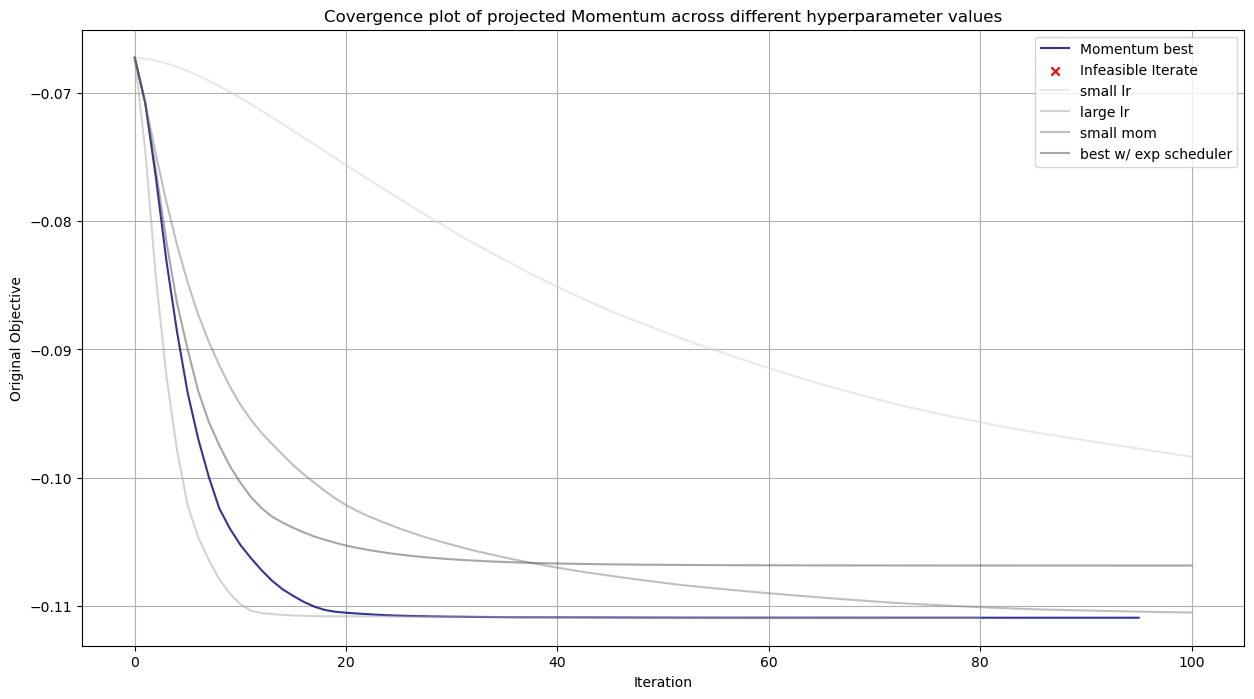

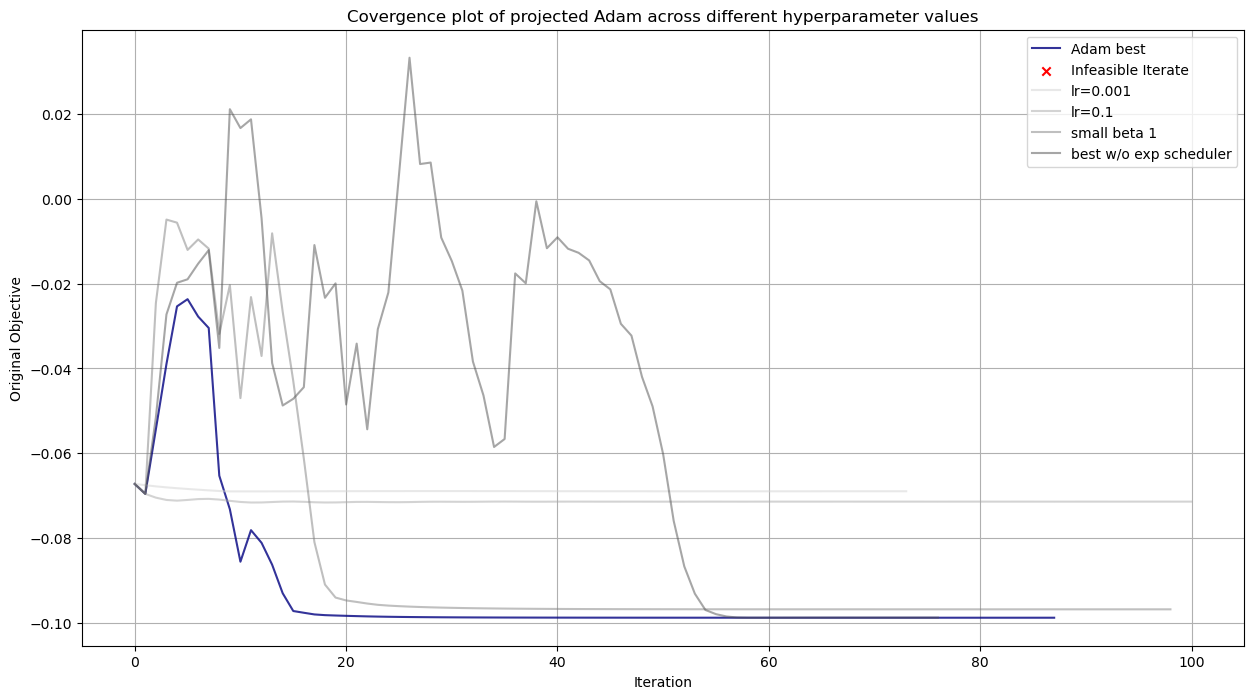

In [9]:
convergence_plot('Momentum', best_params_mom, max_iter=100)
convergence_plot('Adam', best_params_adam, max_iter=100)

### Plotting the two models together with there best parameter values and report the results

------------------------ Momentum result report ----------------------

------------------------------ Checkpoints --------------------------------------


Iteration,0,20,50,100
Objective,-0.06725,-0.11054,-0.11092,-0.11093
Feasiblity,True,True,True,True
Violation Nonnegativity(Before),0.00e+00,0.00e+00,0.00e+00,Early Stop
Violation Budget(Before),0.00e+00,1.69e+00,1.92e+00,Early Stop
Violation Nonnegativity(After),0.00e+00,0.00e+00,0.00e+00,0.00e+00
Violation Budget(After),0.00e+00,2.22e-16,1.11e-16,1.11e-16


,lr,momentum,use_scheduler,gamma
Momentum best params,0.04642,0.9,False,N/A



---------------------Final results and computation costs-------------------------


,Value
Metric,
Final Iteration Reached,95
Wall Clock Time (s),0.0975
nfev (Func Evals),95
njev (Grad Evals),95


------------------------ Adam result report ----------------------

------------------------------ Checkpoints --------------------------------------


Iteration,0,20,50,100
Objective,-0.06725,-0.09836,-0.09880,-0.09881
Feasiblity,True,True,True,True
Violation Nonnegativity(Before),0.00e+00,0.00e+00,0.00e+00,Early Stop
Violation Budget(Before),0.00e+00,2.02e+00,9.55e-02,Early Stop
Violation Nonnegativity(After),0.00e+00,0.00e+00,0.00e+00,0.00e+00
Violation Budget(After),0.00e+00,4.44e-16,2.22e-16,1.11e-16


,lr,beta1,use_scheduler,gamma
Momentum best params,0.3162,0.3,True,0.9



---------------------Final results and computation costs-------------------------


,Value
Metric,
Final Iteration Reached,87
Wall Clock Time (s),0.1084
nfev (Func Evals),87
njev (Grad Evals),87


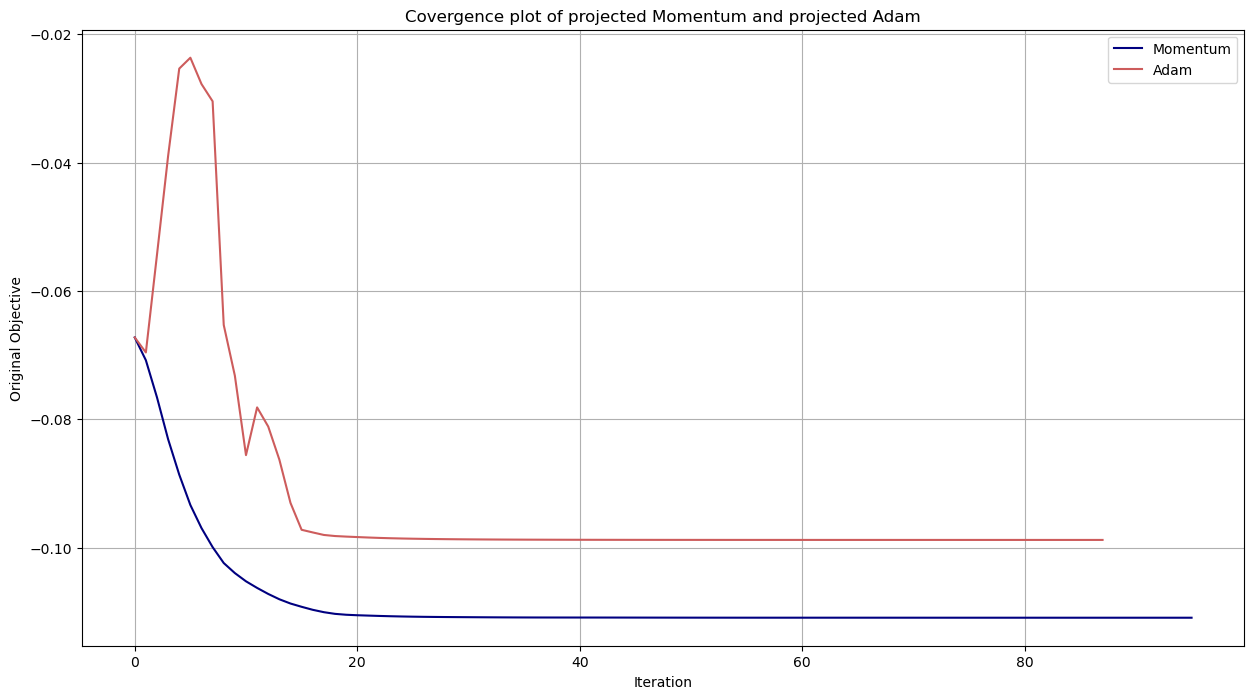

In [10]:
lst_params=[best_params_mom,best_params_adam]
optimizer_names=['Momentum','Adam']
colors=['navy','indianred']
ax=plt.subplots(figsize=(15,8))[1]
for idx,params in enumerate(lst_params):
    res=run_projected_method(optimizer_names[idx], params, max_iter=100)
    # append the results to the portfolio results dictionary
    portfolio_results['Projected '+optimizer_names[idx]]=res['final_weights']
    # report the checkpoints and other results
    print(f"------------------------ {optimizer_names[idx]} result report ----------------------")
    cp = res['checkpoints']
    # check for early termination
    actual_final_iter = res['final results']['final iteration']
    cp_table = []
    for step in [0, 20, 50, 100]:
        if step in cp and cp[step]:
            obj = cp[step].get('objective', None)
            feasible = cp[step].get('feasibility', None)
            v_before_neg = cp[step]['violations before projection']['nonnegative_violation']
            v_before_budget = cp[step]['violations before projection']['budget_violation']
            v_after_neg = cp[step]['violations after projection']['nonnegative_violation']
            v_after_budget = cp[step]['violations after projection']['budget_violation']
        else:   
            # Use final results if terminated early
            if step == 100 and actual_final_iter < 100:
                obj = res['final results']['objective value']
                feasible = res['final results']['feasibility']
                v_before_neg = 'Early Stop'
                v_before_budget = 'Early Stop'
                v_after_neg = res['final results']['violations']['nonnegative_violation']
                v_after_budget = res['final results']['violations']['budget_violation']
                
        cp_table.append({
            'Iteration': step,
            'Objective': f"{obj:.5f}" if obj is not None else 'N/A',
            'Feasiblity': feasible,
            'Violation Nonnegativity(Before)': f"{v_before_neg:.2e}" if isinstance(v_before_neg, float) else v_before_neg,
            'Violation Budget(Before)': f"{v_before_budget:.2e}" if isinstance(v_before_budget, float) else v_before_budget,
            'Violation Nonnegativity(After)': f"{v_after_neg:.2e}" if isinstance(v_after_neg, float) else v_after_neg,
            'Violation Budget(After)': f"{v_after_budget:.2e}" if isinstance(v_after_budget, float) else v_after_budget
        })

    df_cp = pd.DataFrame(cp_table).set_index('Iteration')
    print("\n------------------------------ Checkpoints --------------------------------------")
    display(df_cp.T) 

    # extract best params
    clean_dict = {}
    for k, v in res['hyperparams'].items():
        if k=='gamma' and not res['hyperparams'].get('use_scheduler', False):
            clean_dict['gamma']='N/A'
        else:
            if isinstance(v, (float, np.floating)):
                clean_dict[k]= f"{v:.4g}" 
            else:
                clean_dict[k]=v
    df_params=pd.DataFrame(clean_dict,index=['Momentum best params'])
    display(df_params)
    # Other entries in res
    print('\n---------------------Final results and computation costs-------------------------')
    summary_dict = {
        'Final Iteration Reached': actual_final_iter,
        'Wall Clock Time (s)': f"{res['wall_clock_time']:.4f}",
        'nfev (Func Evals)': res['eval_counts']['nfev'],
        'njev (Grad Evals)': res['eval_counts']['njev'],
    }
    df_summary = pd.DataFrame(list(summary_dict.items()), columns=['Metric', 'Value']).set_index('Metric')
    display(df_summary)
    # plot
    history_obj=res['history']['objective']
    feasible_iter=res['history']['feasibility']
    iters=np.arange(len(history_obj))
    ax.plot(iters,history_obj,color=colors[idx],label=optimizer_names[idx],alpha=1)
    infeasible_iter=iters[~feasible_iter]
    infeasible_obj=history_obj[~feasible_iter]
    ax.scatter(infeasible_iter,infeasible_obj,color='red',marker='x')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Original Objective')
    ax.set_title(f'Covergence plot of projected Momentum and projected Adam')
    ax.legend()
plt.grid(True)
plt.show()


**Summary of results**
Because of manual projection, all iterations ends up feasible, while the results compute two sets onf violation metrics: before and after proejction to show the effect of projection. It could be noted that the budget constraint is often violated and relys on projection to ends up feasible.

**Projected Momentum performs better**
Projected Momentum successfully converged to -0.1109 (matching the CVXPY benchmark) within 15-20 iterations, and early terminates at iteration 95(under the condition gradient decrease less than $10^{-8}$ between two iterations). The use of a constant learning rate (lr=0.046) combined with a high momentum (0.9) allowed the algorithm to smoothly "slide" into the valley, it has consistently lower objective value than Adam at all checkpoints

**Projected Adam**
Adam computes independent adaptive step sizes for each weight.However, the portfolio problem has highly coupled gradients (dictated by the covariance matrix and a strict budget constraint).The simplex projection forces the weights back onto the boundary, which severely disrupts Adam's independently scaled update direction. Adam also requires an artificially high learning rate to make progress in 100 steps, which triggers massive early oscillations.

**Computational costs**
The wall-clock time are around the same for them. While Projected Momentum is faster in terms of time per iteration

### A cvxpy solution reference

In [11]:
import cvxpy as cp
w = cp.Variable(n_assets)
objective = cp.Minimize(-mu.T @ w + 0.5 * gamma * cp.quad_form(w, Sigma))
constraints = [w >= 0,cp.sum(w) == 1]
prob = cp.Problem(objective, constraints)
start_time = time.time()
prob.solve(solver=cp.OSQP,verbose=False)
benchmark_time = time.time() - start_time
if prob.status == cp.OPTIMAL:
    w_opt = w.value
    obj_val = prob.value
    violation = max(np.maximum(-w_opt, 0).max(), abs(w_opt.sum() - 1))
    print(f"Objective: {obj_val:.6f}")
    print(f"time: {benchmark_time:.4f}")
    print(f"Violation: {violation:.2e}")
else:
    print(f'{prob.status}')

Objective: -0.110931
time: 0.0713
Violation: 2.22e-16


---
# Problem 2 — Smooth Nonconvex Optimization: A Fixed Neural Network

### Background (no prior neural-network knowledge required)

A small prediction model maps eight market features $x\in\mathbb R^8$ to a predicted short-horizon financial signal. The model is a **two-layer neural network**, but **you do not need to know how neural networks are trained** for this project: the prediction formula, loss function, and complete PyTorch implementation are already provided.

Treat the entire model as a **fixed differentiable function of a parameter vector** $\theta\in\mathbb R^{241}$. Your task is only to optimize $\theta$.

With hidden width $m=24$, define

$$
\widehat y_\theta(x)=a^\top\tanh(Wx+b)+c,
$$

where $W\in\mathbb R^{24\times8}$, $b,a\in\mathbb R^{24}$, $c\in\mathbb R$, and $\theta$ concatenates all these parameters. The activation $\tanh$ is applied coordinate-wise.

Given fixed observations $(x_i,y_i)$, minimize

$$
\boxed{L(\theta)=\frac1N\sum_{i=1}^N(\widehat y_\theta(x_i)-y_i)^2
+\frac\lambda2\|\theta\|_2^2},\qquad\lambda=10^{-4}.
$$

This function is **smooth but generally nonconvex** in $\theta$. Autograd computes the gradient; you do **not** need to derive derivatives through the network.

**Fixed problem:** $N=512$ observations; eight features; 241 parameters. Do not change the data, model, objective, coefficient $\lambda$, or initialization. You may change the optimizer and its settings.

In [5]:
# Fixed nonconvex data and initialization — do not modify.
rng_nn = np.random.default_rng(4501)
N, d_in, hidden_width = 512, 8, 24
X_np = rng_nn.normal(size=(N, d_in))
u = rng_nn.normal(size=d_in)
v = rng_nn.normal(size=d_in)
y_np = (1.25 * np.tanh(X_np @ u / np.sqrt(d_in))
        + 0.6 * np.sin(X_np @ v / np.sqrt(d_in))
        + 0.25 * X_np[:, 0] * X_np[:, 1]
        + 0.08 * rng_nn.normal(size=N))

X_train = torch.tensor(X_np, dtype=torch.float64)
y_train = torch.tensor(y_np, dtype=torch.float64)
lam = 1e-4

rng_init = np.random.default_rng(4502)
W_init = rng_init.normal(scale=0.24, size=(hidden_width, d_in))
b_init = np.zeros(hidden_width)
a_init = rng_init.normal(scale=0.18, size=hidden_width)
c_init = np.array([0.0])
theta_initial_np = np.concatenate([
    W_init.reshape(-1), b_init, a_init, c_init
])
theta_initial = torch.tensor(theta_initial_np, dtype=torch.float64)

assert theta_initial.numel() == 241
print('Training observations:', N)
print('Trainable parameters:', theta_initial.numel())

Training observations: 512
Trainable parameters: 241


In [6]:
# Fully specified model and objective: treat L(theta) as a black box.
# There is no need to use torch.nn, construct a model, or derive gradients.
def nn_predictions(theta, X):
    m, d = hidden_width, d_in
    W = theta[:m*d].reshape(m, d)
    b = theta[m*d:m*d + m]
    a = theta[m*d + m:m*d + 2*m]
    c = theta[-1]
    return torch.tanh(X @ W.T + b) @ a + c

def nn_objective(theta, X=X_train, y=y_train):
    predictions = nn_predictions(theta, X)
    mse = ((predictions - y) ** 2).mean()
    regularizer = (lam / 2) * (theta ** 2).sum()
    return mse + regularizer

def fresh_theta():
    """Start a new optimizer at exactly the prescribed parameter vector."""
    return theta_initial.detach().clone().requires_grad_(True)

@torch.no_grad()
def nn_score(theta):
    """Evaluate the ORIGINAL FULL-DATA objective for reporting."""
    return float(nn_objective(theta, X_train, y_train).item())

print('Initial nonconvex objective:', nn_score(fresh_theta()))
assert abs(nn_score(fresh_theta()) - nn_score(fresh_theta())) < 1e-12

Initial nonconvex objective: 1.0540702245853104


### Task 2 — Required algorithm comparisons (200 parameter updates)

**Every team must attempt all of the following:**

1. **Full-batch Gradient Descent**, using `torch.optim.SGD` with momentum set to zero.
2. **Mini-batch SGD**, using the same objective but stochastic batches of observations.
3. **SGD with Momentum**, using `torch.optim.SGD(momentum=...)`.
4. **AdaGrad**, using `torch.optim.Adagrad`.
5. **Adam**, using `torch.optim.Adam`.
6. **PyTorch L-BFGS**, using `torch.optim.LBFGS` and a correctly defined closure.
7. **SciPy BFGS**, using `scipy.optimize.minimize(method='BFGS')` with an appropriate objective and gradient interface.

All of these algorithms can be used on the supplied parameter vector `theta` without needing a neural-network API. You may additionally try a manually implemented method, Newton-type methods, alternative step-size schedules, or other reasonable optimizers, but those additions do not replace the required comparisons.

**Experiment requirements**

- For **every run**, initialize from `fresh_theta()`. For SciPy, use the same initial numerical vector `theta_initial_np`.
- Tune hyperparameters systematically: learning rate and schedule, momentum coefficient, minibatch size, L-BFGS history/line search, or solver tolerances as applicable.
- Use a budget of **200 parameter updates/optimizer iterations**. Report the **full training objective** at iterations/updates **0, 20, 50, 100, and 200**, with time and function/gradient evaluation counts when available. If a solver stops early, record the stopping iteration and carry its final value forward for the comparison.
- For mini-batch methods, use a fixed random seed to ensure reproducibility. At each checkpoint, evaluate and report the original objective function using the **entire training dataset**, rather than the loss computed on the current mini-batch.
- For L-BFGS and other built-in quasi-Newton solvers, you may use their default or tuned iteration and line-search settings. Since a single iteration may involve multiple objective and gradient evaluations, report the number of iterations (`nit`), function evaluations (`nfev`), and gradient evaluations (`njev`) when available, or the number of closure evaluations for PyTorch L-BFGS. Also report the runtime to help compare computational efficiency across methods.
- The objective *already includes* $\frac\lambda2\|\theta\|^2$. Keep optimizer `weight_decay=0` to avoid changing or double-counting the prescribed regularizer.
- Explain how optimizer choice and learning-rate tuning affect the **objective after a fixed update budget**. Compare runtime and evaluation counts separately.

**You do not need to change or understand the internal structure of `nn_predictions`.** Treat `nn_objective(theta)` as the provided differentiable objective and let PyTorch compute its derivatives.

In [7]:
# TODO — Problem 2
# Use nn_objective(theta) as the optimization objective.
# Use fresh_theta() at the start of every experiment.
# Implement and tune every required method listed above.
# Evaluate the original full objective using nn_score(theta).

nn_results = {}

---
# Results, Comparisons, and Discussion

Submit a comparison table and a convergence plot for each problem. Include hyperparameter-search information (which settings you tried and how you selected the final settings), **not just the best run**.

### Problem 1 — Convex Portfolio

| Required method | Best hyperparameters | Objective @ 20 | @ 50 | @ 100 | Feasible @ 100? | Violations | Time / evaluations |
|---|---|---:|---:|---:|---|---|---|
| Manual PGD | | | | | | | |
| Projected Momentum |lr=0.046,momentum=0.9,no schedular |-0.11054 |-0.11092 |-0.11093 |Yes| 1.11e-16(budget)| 0.1080s/95 |
| Projected Adam |lr=0.3162, $\beta_{1}$=0.3, $\gamma$=0.9 |-0.09836 |-0.09880 |-0.09881 |Yes | 1.11e-16(budget) | 0.1103/87 |
| SciPy constrained solver | | | | | | | |
| Squared-penalty method | | | | | | | |

### Problem 2 — Nonconvex Model Fitting

| Required method | Best hyperparameters | Objective @ 20 | @ 50 | @ 100 | @ 200 | Time / evaluations |
|---|---|---:|---:|---:|---:|---|
| Full-batch GD | | | | | | |
| Mini-batch SGD | | | | | | |
| Momentum | | | | | | |
| AdaGrad | | | | | | |
| Adam | | | | | | |
| PyTorch L-BFGS | | | | | | |
| SciPy BFGS | | | | | | |

### Discussion questions

1. **Manual implementation:** Describe how you implemented PGD, including the projection and stopping/monitoring logic. How did you verify correctness?
2. **Convex portfolio:** Which approach achieves the lowest **feasible** objective within 100 iterations? How does the penalty method trade off objective improvement and constraint violation?
3. **Nonconvex objective:** Which optimizer achieves the lowest full-data objective after 200 updates? Which hyperparameters mattered most? Did different methods show different convergence patterns?
4. **Budget fairness:** Compare iterations, objective/gradient evaluations, and wall-clock time. Why do these measures give different perspectives on efficiency?
5. **Practical choice:** Which built-in method would you use for each problem in practice, and when is a custom implementation justified?

**Evaluation:** Compare the **feasible original objective after a fixed iteration budget** for the projected first-order portfolio methods, and the **full original objective after the fixed update budget** for the nonconvex problem. Dedicated constrained solvers provide a portfolio accuracy benchmark; penalty methods also receive a feasibility analysis. Correct manual implementation, comprehensive comparisons, tuning, reproducibility, and explanations are all required.

2. **Convex portfolio comparison**

**Projected Momentum performs better**
Projected Momentum successfully converged to -0.1109 (matching the CVXPY benchmark) within 15-20 iterations, and early terminates at iteration 95(under the condition gradient decrease less than $10^{-8}$ between two iterations). The use of a constant learning rate (lr=0.046) combined with a high momentum (0.9) allowed the algorithm to smoothly "slide" into the valley, it has consistently lower objective value than Adam at all checkpoints

**Projected Adam**
Adam did not coverge well to the global optimum, ending up around -0.0988. It computes independent adaptive step sizes for each weight.However, the portfolio problem has highly coupled gradients (dictated by the covariance matrix and a strict budget constraint).The simplex projection forces the weights back onto the boundary, which severely disrupts Adam's independently scaled update direction. Adam also requires an artificially high learning rate to make progress in 100 steps, which triggers massive early oscillations.